# Description

Exercise #1 from #381: distribution of the PnL as a function of the hit
rate.

- Load close prices for a coin at a given sampling frequency
- Compute returns with `pct_change()`
- Simulate a predictor with a given hit rate: a correct call earns |r| and a
  wrong call loses |r|
- Plot the PnL distribution and P(PnL > 0) as the hit rate changes
- Repeat for different coins and sampling frequencies

Two ways of drawing the hits are compared:
- "shuffle": exactly round(hit_rate * N) hits in random order (Exercise #1)
- "bernoulli": each call is correct with probability hit_rate (spec
  formalization)

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import tradability_utils as tu

## Config

Change the coins, frequencies, and hit rates here.

In [2]:
SYMBOLS = ["BTCUSDT", "ETHUSDT"]
INTERVALS = ["1h", "1d"]
START = "2020-01-01"
END = "2026-10-01"
HIT_RATES = [0.48, 0.49, 0.50, 0.51, 0.52, 0.53, 0.55]
N_SIMS = 1000
MODES = ["shuffle", "bernoulli"]
# All (coin, frequency) pairs, one subplot each.
PAIRS = [(symbol, interval) for symbol in SYMBOLS for interval in INTERVALS]

## Simulate the PnL

In [3]:
# Run the experiment for every coin, frequency, and mode.
results = []
for symbol, interval in PAIRS:
    for mode in MODES:
        df = tu.run_experiment(
            symbol, interval, START, END, HIT_RATES, N_SIMS, mode=mode
        )
        results.append(df)
results = pd.concat(results, ignore_index=True)
# Show the number of trades for each coin and frequency.
n_trades = results.groupby(["symbol", "interval"])["n_trades"].first()
n_trades

symbol   interval
BTCUSDT  1d           2464
         1h          59127
ETHUSDT  1d           2464
         1h          59127
Name: n_trades, dtype: int64

## PnL distribution vs hit rate

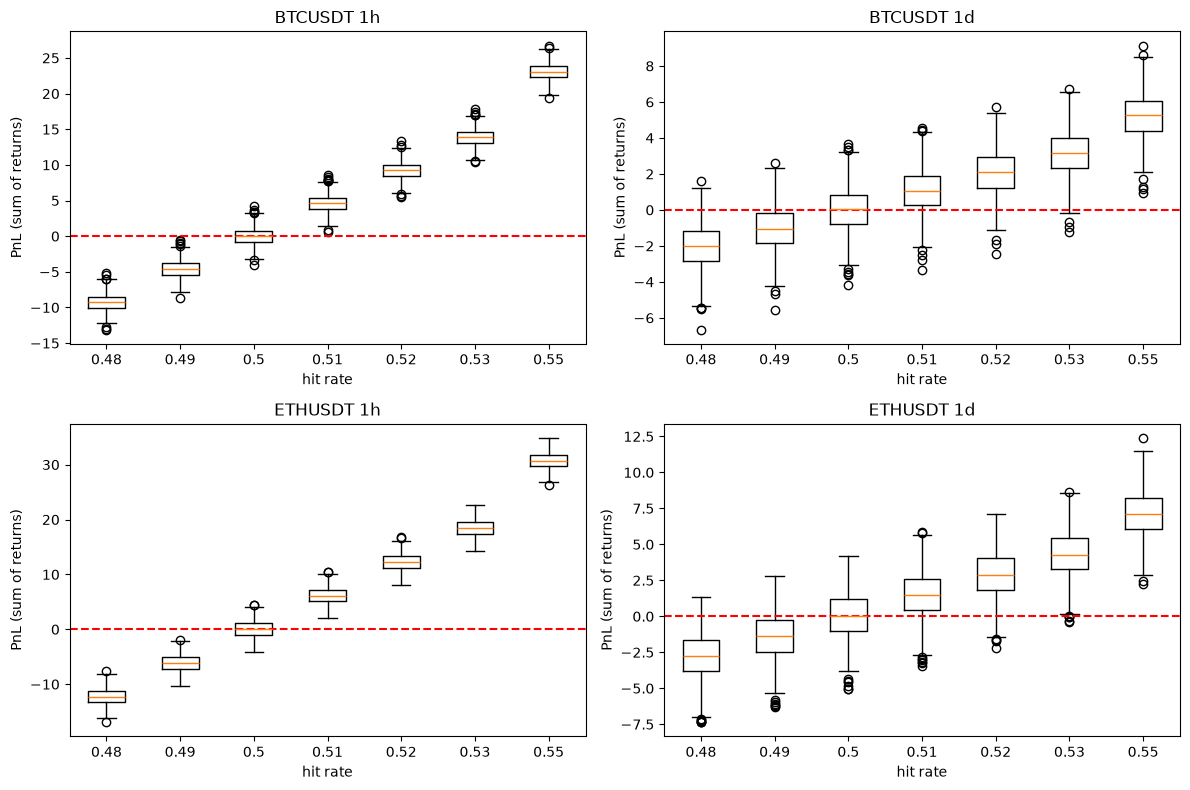

In [4]:
# Plot one box per hit rate for each coin and frequency.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (symbol, interval) in zip(axes.flat, PAIRS):
    mask = (
        (results["symbol"] == symbol)
        & (results["interval"] == interval)
        & (results["mode"] == "shuffle")
    )
    sub = results[mask]
    data = [sub[sub["hit_rate"] == hit_rate]["pnl"] for hit_rate in HIT_RATES]
    ax.boxplot(data, tick_labels=HIT_RATES)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(f"{symbol} {interval}")
    ax.set_xlabel("hit rate")
    ax.set_ylabel("PnL (sum of returns)")
plt.tight_layout()
plt.show()

## Probability of a positive PnL vs hit rate

The dotted line is the spec formula for a 95% chance of positive PnL:
$p^* \approx \frac{1}{2} + \frac{z_q}{2 \sqrt{N}}$ with $z_q = 1.645$.

In [5]:
# Compute P(PnL > 0) for each coin, frequency, mode, and hit rate.
prob = (
    results.assign(win=results["pnl"] > 0)
    .groupby(["symbol", "interval", "mode", "hit_rate"])["win"]
    .mean()
    .reset_index()
)
prob.pivot_table(
    index=["symbol", "interval", "mode"], columns="hit_rate", values="win"
)

hit_rate                     0.48   0.49   0.50   0.51   0.52   0.53   0.55
symbol  interval mode                                                      
BTCUSDT 1d       bernoulli  0.093  0.253  0.503  0.738  0.883  0.976  0.999
                 shuffle    0.046  0.211  0.515  0.820  0.957  0.995  1.000
        1h       bernoulli  0.000  0.001  0.505  0.999  1.000  1.000  1.000
                 shuffle    0.000  0.000  0.501  1.000  1.000  1.000  1.000
ETHUSDT 1d       bernoulli  0.099  0.250  0.505  0.725  0.901  0.980  0.999
                 shuffle    0.038  0.204  0.503  0.830  0.964  0.996  1.000
        1h       bernoulli  0.000  0.002  0.507  0.999  1.000  1.000  1.000
                 shuffle    0.000  0.000  0.504  1.000  1.000  1.000  1.000

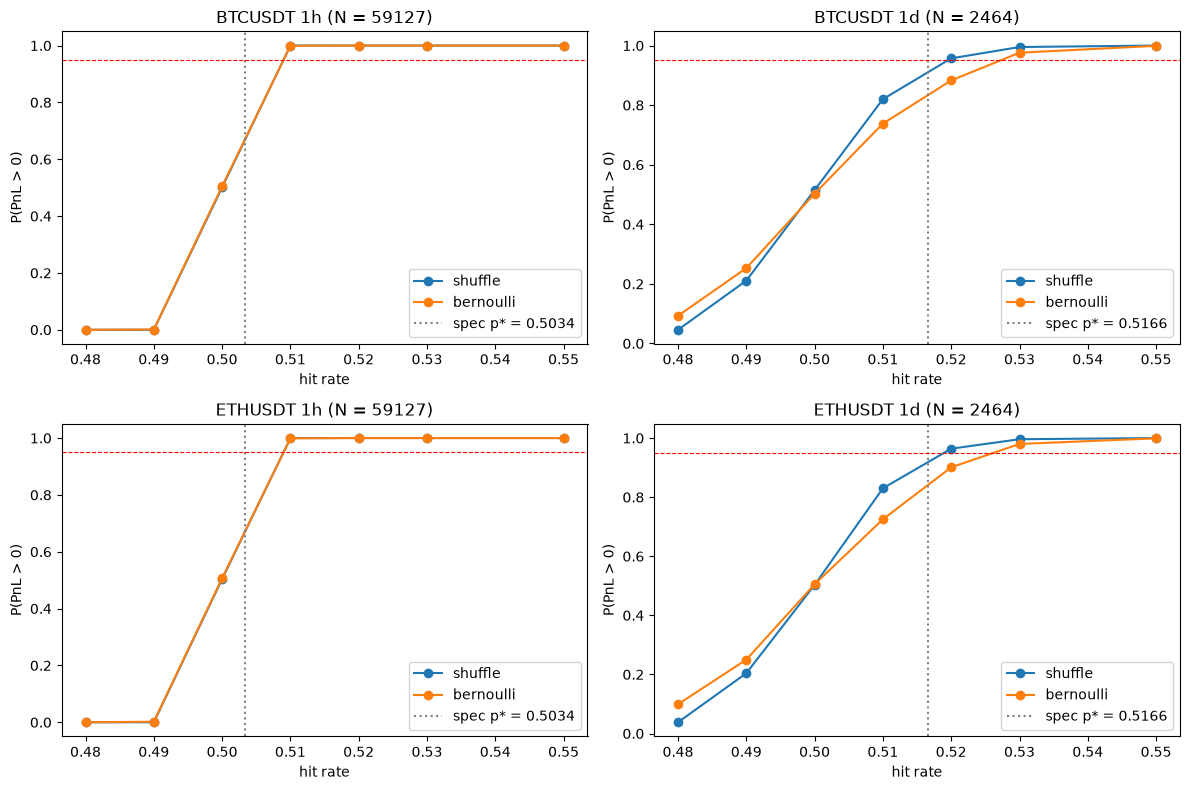

In [6]:
# Plot P(PnL > 0) for both modes against the spec formula.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (symbol, interval) in zip(axes.flat, PAIRS):
    for mode in MODES:
        mask = (
            (prob["symbol"] == symbol)
            & (prob["interval"] == interval)
            & (prob["mode"] == mode)
        )
        sub = prob[mask]
        ax.plot(sub["hit_rate"], sub["win"], marker="o", label=mode)
    n = n_trades[(symbol, interval)]
    p_star = 0.5 + 1.645 / (2 * np.sqrt(n))
    label = f"spec p* = {p_star:.4f}"
    ax.axvline(p_star, color="gray", linestyle=":", label=label)
    ax.axhline(0.95, color="red", linestyle="--", linewidth=0.8)
    ax.set_title(f"{symbol} {interval} (N = {n})")
    ax.set_xlabel("hit rate")
    ax.set_ylabel("P(PnL > 0)")
    ax.legend()
plt.tight_layout()
plt.show()

## Observations

- Median PnL is almost exactly (2p − 1) · Σ|r|, and at p = 0.50 it's centered at 0, so the simulation has no bias.
- 1h is much more reliable than 1d because it has ~24× more trades over the same 6.75 years: at 51% the hourly PnL was positive in every simulation, while daily was positive only ~75-80% of the time.
- ETH makes more PnL than BTC for the same hit rate (bigger moves), but the probability of profit is almost the same for both.
- At 1d, "shuffle" (fixed number of wins, as in Exercise #1) needs ~0.52 for a 95% chance of profit, while "bernoulli" (as in the spec) needs ~0.525.
- The spec formula p* = 1/2 + 1.645 / (2√N) is too optimistic because returns have fat tails. Using an effective N = (Σ|r|)² / Σr² instead (~1,100 for 1d, ~21,000 for 1h, vs 2,464 and 59,127) gives p* ≈ 0.525 for 1d, which matches the simulation.